In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ForTP3 import *


# Chargement de l'environement

In [2]:

try:
    with open('maze.pkl', 'rb') as f:
        Maze = pickle.load(f)
except FileNotFoundError:
    # create a new maze if the file does not exist
    app = App()
    app.mainloop()
    Maze=app.A

    # Save the generated maze
    with open('maze.pkl', 'wb') as f:
        pickle.dump(Maze, f)




actions  = ["UP", "DOWN", "LEFT", "RIGHT"]
states,exit_state,init_states = get_states_from_Maze(Maze)
states = list(map(lambda x: (int(x[0]), int(x[1])), states))  # Convert states to a list of tuples for consistent indexing
init_state = init_states[np.random.randint(len(init_states))]
try :
    with open('episode.pkl', 'rb') as f:
        episode = pickle.load(f)
except FileNotFoundError:
    # create a new episode if the file does not exist
    episode = generate_episode(init_state, actions, Maze, exit_state, itermax=100*len(states))

# Save the generated episode
with open('episode.pkl', 'wb') as f:
    pickle.dump(episode, f)


for step in episode:
    print(step)

    

(array([8, 6]), 'UP', 0, array([7, 6]))
(array([7, 6]), 'UP', 0, array([6, 6]))
(array([6, 6]), 'UP', 0, array([5, 6]))
(array([5, 6]), 'DOWN', 0, array([6, 6]))
(array([6, 6]), 'DOWN', 0, array([7, 6]))
(array([7, 6]), 'UP', 0, array([6, 6]))
(array([6, 6]), 'UP', 0, array([5, 6]))
(array([5, 6]), 'UP', 0, array([4, 6]))
(array([4, 6]), 'DOWN', 0, array([5, 6]))
(array([5, 6]), 'DOWN', 0, array([6, 6]))
(array([6, 6]), 'UP', 0, array([5, 6]))
(array([5, 6]), 'DOWN', 0, array([6, 6]))
(array([6, 6]), 'DOWN', 0, array([7, 6]))
(array([7, 6]), 'DOWN', 0, array([8, 6]))
(array([8, 6]), 'DOWN', 0, array([9, 6]))
(array([9, 6]), 'DOWN', 0, array([10,  6]))
(array([10,  6]), 'LEFT', 0, array([10,  5]))
(array([10,  5]), 'LEFT', 0, array([10,  4]))
(array([10,  4]), 'RIGHT', 0, array([10,  5]))
(array([10,  5]), 'LEFT', 0, array([10,  4]))
(array([10,  4]), 'LEFT', 0, array([10,  3]))
(array([10,  3]), 'LEFT', 0, array([10,  2]))
(array([10,  2]), 'RIGHT', 0, array([10,  3]))
(array([10,  3])

# Fonction utile


## Visualisation

In [3]:



def plot_policy(Maze,states, actions, pi):
    direction_map = {
        'UP': '↑',
        'RIGHT': '→',
        'DOWN': '↓',
        'LEFT': '←'
        
    }
    policy_grid = np.full((len(Maze), len(Maze[0])), ' ')
    _,  exit_state, _ = get_states_from_Maze(Maze)
    for s in range(len(states)):
        best_action = pi[s]
        state_coords = states[s]
        policy_grid[state_coords] = direction_map[actions[best_action]]  # Use the first letter of the action
        if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  # If it's the exit state, no action is needed
            policy_grid[state_coords] = 'E'  # Mark the exit state with 'E'
    plt.imshow(Maze, cmap='gray')
    for i in range(len(Maze)):
        for j in range(len(Maze[0])):
            plt.text(j, i, policy_grid[i][j], ha='center', va='center', color='red')
    

def plot_values(Maze, first_visit_values):
	states, exit_state, init_states = get_states_from_Maze(Maze)
	plt.figure(figsize=(15, 10))
	plt.imshow(Maze, cmap='gray', origin='upper')
	for idx, state in enumerate(states):
		if state[0] == exit_state[0] and state[1] == exit_state[1]: 
			continue  
		plt.text(state[1], state[0], f'{first_visit_values[idx]:.2f}', ha='center', va='center', color='green')
	
	plt.text(exit_state[1], exit_state[0], 'E', ha='center', va='center', color='red')


## generation d'episode 

In [4]:
def process_episode(episode_t):
    state, action, reward, next_state = episode_t
    state = (int(state[0]), int(state[1]))  
    state = states.index(state)  
    action = actions.index(action)  
    next_state = (int(next_state[0]), int(next_state[1]))  
    next_state = states.index(next_state)  
    return state, action, reward, next_state

def generate_episode_from_policy(init_state, Maze, actions, pi=None, iter_max=1000):
    #from init_state to exit_state in maze M
    # list of (state, action, reward, next_state)
    # pi is a policy mapping states to action indice
    states, exit_state, _ = get_states_from_Maze(Maze)
    states = list(map(lambda x: (int(x[0]), int(x[1])), states))  # Convert states to a list of tuples for consistent indexing
    i=0
    current_state = np.copy(init_state)
    s = states.index((current_state[0], current_state[1]))
    episode = list()
    
    while  i < iter_max and not all(current_state == exit_state)  :      
        current_actions = get_actions(current_state,actions,Maze)
        if pi is None:
            action = np.random.choice(current_actions)
        else:
            action = pi[s]
            if action not in current_actions:
                action = np.random.choice(current_actions)
                
        new_state, reward= next_state(current_state, action, exit_state, Maze)
        episode.append((current_state,action, reward, new_state))
        current_state = new_state
        s = states.index((current_state[0], current_state[1]))
        i=i+1
    if current_state[0]== exit_state[0] and current_state[1] == exit_state[1]:
        return episode
    return []


## generation de police

In [5]:
def get_greedy_policy(q_s_a):
    # Get the greedy policy from Q(s,a)
	pi = np.zeros(len(q_s_a), dtype=int)



	for s in range(len(states)):
		if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  # If it's the exit state, no action is needed
			pi[s] = 0  # Indicate no action for the exit state
			continue
		possible_actions = get_actions(states[s], actions, Maze)
		possible_q_values = [actions.index(a) for a in possible_actions]
		action_pi = { a: q_s_a[s][a] for a in possible_q_values }

		pi[s] = max(action_pi, key=action_pi.get)  # Choose the action with the highest Q-value
	return pi

def get_epsilon_greedy_policy(q_s_a, states, epsilon):
	pi = np.zeros(len(q_s_a), dtype=int)
	
	for s in range(len(states)):
		if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]: 
			pi[s] = 0 
			continue
		possible_actions = get_actions(states[s], actions, Maze)
		possible_q_values = [actions.index(a) for a in possible_actions]
		action_pi = { a: q_s_a[s][a] for a in possible_q_values }
		
		if np.random.rand() < epsilon:
			pi[s] = np.random.choice(possible_q_values)  # Explore: choose a random action
		else:
			pi[s] = max(action_pi, key=action_pi.get)  # Exploit: choose the action with the highest Q-value
			
	return pi

def generate_random_e_soft_policy(states, actions, epsilon):
	pi = np.zeros(len(states), dtype=int)
	for s in range(len(states)):
		if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  # If it's the exit state, no action is needed
			pi[s] = 0  # Indicate no action for the exit state
			continue
		possible_actions = get_actions(states[s], actions, Maze)
		possible_q_values = [actions.index(a) for a in possible_actions]
		if np.random.rand() < epsilon:
			pi[s] = np.random.choice(possible_q_values)  # Explore: choose a random action
		else:
			pi[s] = np.random.choice(possible_q_values)  # Exploit: choose a random action (since we don't have Q-values yet)
	return pi

# td(0) Estimation

In [6]:
def td_zeros_estimation(pi, Maze, alpha=0.1, tau=.9, max_iter=100):


    states, exit_state, init_states = get_states_from_Maze(Maze)
    V = np.zeros(len(states))  #
    for s in range(len(states)):
        if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  
            V[s] = 0  # Set value of exit state to 0
        else:
            V[s] = np.random.rand()
    
    episodes = [
        generate_episode_from_policy(init_states[np.random.randint(len(init_states))],  Maze, actions, pi=pi, iter_max=100) 
        for _ in range(max_iter)]
    for episode in episodes:
        for step in episode:
            state, action, reward, next_state = process_episode(step)
            if states[state][0] == exit_state[0] and states[state][1] == exit_state[1]:  
                break
            V[state] += alpha * (reward + tau*V[next_state] - V[state])
            

    return V




In [7]:
pi = generate_random_e_soft_policy(states, actions, epsilon=0.1)

pi

array([3, 2, 3, 1, 3, 2, 2, 1, 0, 1, 0, 0, 2, 3, 2, 2, 2, 3, 2, 1, 2, 2,
       1, 0, 0, 1, 0, 1, 0, 1, 0, 3, 3, 3, 2, 0, 3, 3, 2, 1, 0, 0, 2, 0,
       3, 3, 2, 1, 2, 3, 0, 3, 2, 0, 0, 3, 3, 1, 3, 0, 0, 0, 3, 2, 2, 2,
       1, 3, 2, 3, 2, 2, 0, 0, 0, 3, 3, 2])

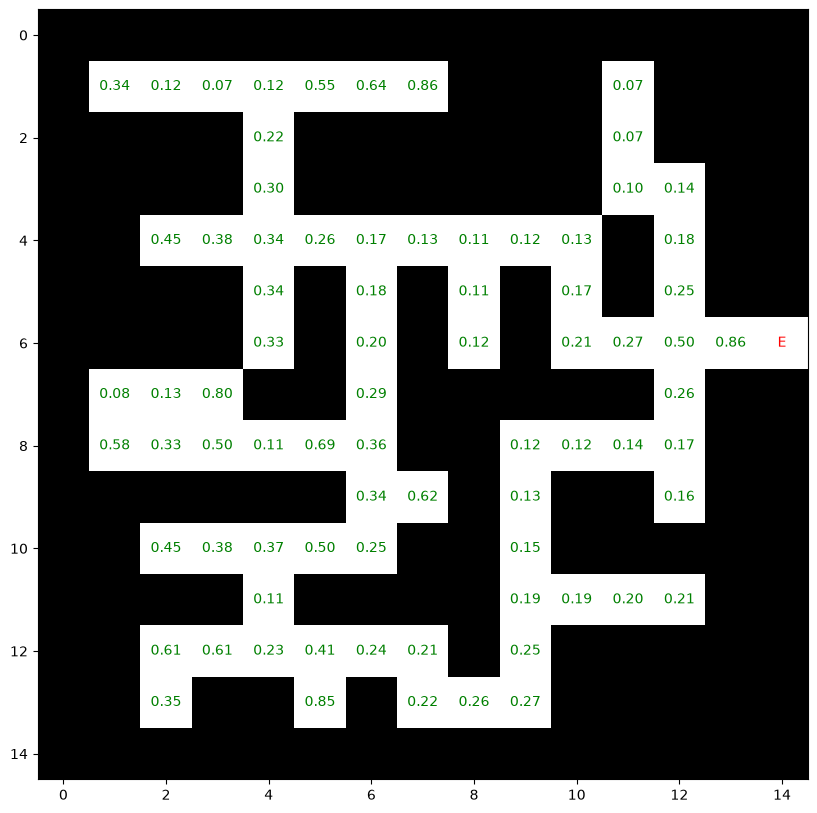

In [8]:
V_pi = td_zeros_estimation(pi, Maze, alpha=0.1, max_iter=1000)

plot_values(Maze, V_pi)

# Algo Sarsa ( a td(0) control )

In [40]:
def sarsa(Maze, actions, alpha, epsilon=0.1, tau=.9, max_iter=1000):


    states, exit_state, init_states = get_states_from_Maze(Maze)
    q_s_a = np.zeros((len(states), len(actions)))
    
    for s in range(len(states)):
        if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  
            continue  # Skip the exit state
        q_s_a[s] = np.random.rand(len(actions))
    pi = get_epsilon_greedy_policy(q_s_a, states, epsilon)

    
    episodes = [
        generate_episode_from_policy(init_states[np.random.randint(len(init_states))],  Maze, actions, pi=pi, iter_max=100) 
        for _ in range(max_iter)
        ]
    for episode in episodes:
        for step in episode:
            state, action, reward, next_state = process_episode(step)
            if states[state][0] == exit_state[0] and states[state][1] == exit_state[1]:  
                break
            next_action = pi[next_state]
            # print(state, action, reward, next_state, next_action)
            q_s_a[state, action] += alpha *(reward + tau*q_s_a[next_state, next_action] - q_s_a[state, action])
        
        pi = get_epsilon_greedy_policy(q_s_a, states, epsilon)
            
            

    return pi, q_s_a

In [41]:
alpha = .1

epsilon = .1

tau = .9

pi, q_s_a = sarsa(Maze, actions, alpha=alpha, epsilon=epsilon, tau=tau, max_iter=1000)

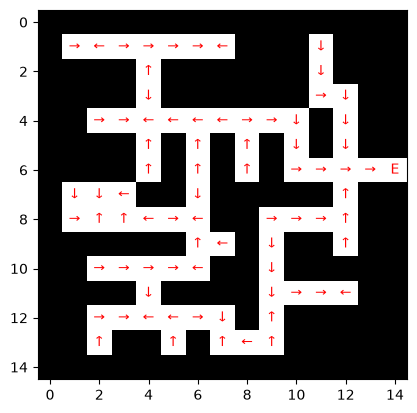

In [42]:
plot_policy(Maze, states, actions, pi)

In [43]:
from concurrent.futures import ThreadPoolExecutor

In [44]:
# alphas = [0.1, 0.3, 0.5, 0.7, 0.9, 1]
# with ThreadPoolExecutor() as executor:
#     futures = [executor.submit(sarsa, Maze, actions, alpha=alpha, epsilon=epsilon, tau=tau, max_iter=1000) for alpha in alphas]
#     results = [future.result() for future in futures]
#     futures = [executor.submit(td_zeros_estimation, pi, Maze, alpha=alpha, max_iter=1000) for pi, q in results]
#     v_pis = [future.result() for future in futures]

# results = list(zip(alphas, results, v_pis))

In [45]:
alphas = [0.1, 0.3, 0.5, 0.7, 0.9, 1]
results = []
for alpha in alphas:
    pi, q_s_a = sarsa(Maze, actions, alpha=alpha, epsilon=epsilon, tau=tau, max_iter=2000)
    v_pi = td_zeros_estimation(pi, Maze, alpha=alpha, max_iter=1000)
    results.append((alpha, pi, q_s_a, sum(v_pi)))  # Store the sum of values for comparison
    

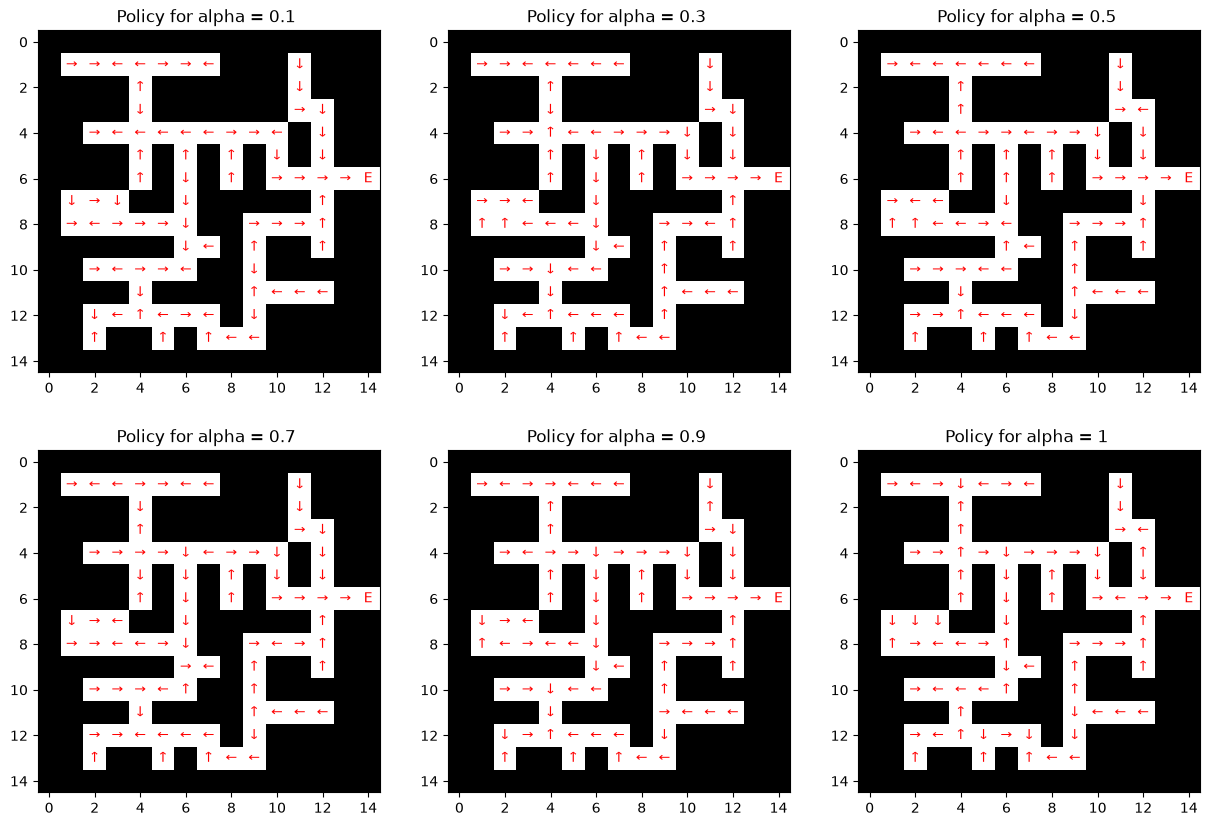

In [46]:

plt.subplots(2, 3, figsize=(15, 10))
for i, alpha in enumerate(alphas):
	# pi, q_s_a = sarsa(Maze, actions, alpha=alpha, epsilon=epsilon, tau=tau, max_iter=1000)
	# V_pi = td_zeros_estimation(pi, Maze, alpha=alpha, max_iter=1000)
	plt.subplot(2, 3, i + 1)
	plt.title(f"Policy for alpha = {alpha} ")
	plot_policy(Maze, states, actions, results[i][1])

Text(0, 0.5, 'Average Steps')

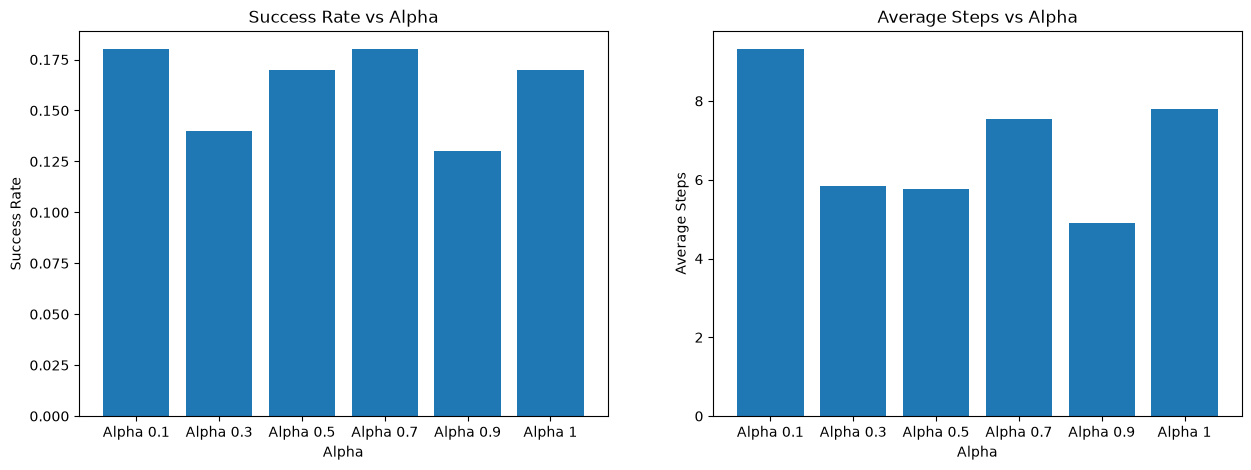

In [47]:
def evaluate_policy(pi, Maze, actions, n_episodes=100, iter_max=100):
    """Evaluate a policy using success rate, return and episode length."""
    _, exit_state, init_states = get_states_from_Maze(Maze)

    returns = []
    lengths = []
    successes = 0

    for i in range(n_episodes):
        init_state = init_states[i % len(init_states)]

        episode = generate_episode_from_policy(
            init_state,
            Maze,
            actions,
            pi=pi,
            iter_max=iter_max
        )

        total_return = sum(step[2] for step in episode)
        returns.append(total_return)
        lengths.append(len(episode))

        if episode:
            final_state = episode[-1][3]
            if tuple(final_state) == tuple(exit_state):
                successes += 1

    return {
        "success_rate": successes / n_episodes,
        "average_return": np.mean(returns),
        "average_steps": np.mean(lengths),
    }



results_evaluation = []
for alpha, pi, q_s_a, _ in results:
    evaluation = evaluate_policy(pi, Maze, actions, n_episodes=100, iter_max=100)
    results_evaluation.append((alpha, evaluation))

# bar plot for success rate, average return, and average steps
success_rates = [evaluation["success_rate"] for _, evaluation in results_evaluation]
average_returns = [evaluation["average_return"] for _, evaluation in results_evaluation]
average_steps = [evaluation["average_steps"] for _, evaluation in results_evaluation]


# bar on one figure with 3 subplots

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.bar([f"Alpha {alpha}" for alpha, _ in results_evaluation], success_rates)
plt.title("Success Rate vs Alpha")
plt.xlabel("Alpha")
plt.ylabel("Success Rate")



plt.subplot(1, 2, 2)
plt.bar([f"Alpha {alpha}" for alpha, _ in results_evaluation], average_steps)
plt.title("Average Steps vs Alpha")
plt.xlabel("Alpha")
plt.ylabel("Average Steps")


# Algo Q-learning

In [48]:
def Q_learning(Maze, actions, alpha, tau=.9, max_iter=1000):


    states, exit_state, init_states = get_states_from_Maze(Maze)
    q_s_a = np.zeros((len(states), len(actions)))
    
    for s in range(len(states)):
        if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  
            continue  # Skip the exit state
        q_s_a[s] = np.random.rand(len(actions))
    pi = get_greedy_policy(q_s_a)

    
    episodes = [
        generate_episode_from_policy(init_states[np.random.randint(len(init_states))],  Maze, actions, pi=pi, iter_max=100) 
        for _ in range(max_iter)
        ]
    for episode in episodes:
        for step in episode:
            state, action, reward, next_state = process_episode(step)
            if states[state][0] == exit_state[0] and states[state][1] == exit_state[1]:  
                break
            next_action = pi[next_state] # the next action is chosen based on the greedy policy derived from the current Q-values
            # print(state, action, reward, next_state, next_action)
            q_s_a[state, action] += alpha *(reward + tau*q_s_a[next_state, next_action] - q_s_a[state, action])
        
        pi = get_greedy_policy(q_s_a)
            
            

    return pi, q_s_a

In [49]:
alpha = .1

epsilon = .1

tau = .9

pi, q_s_a = Q_learning(Maze, actions, alpha=alpha, tau=tau, max_iter=1000)

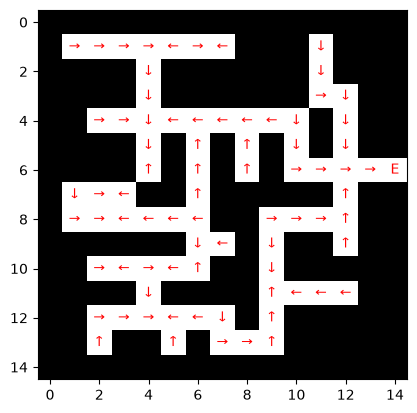

In [50]:
plot_policy(Maze, states, actions, pi)

In [58]:
taus = [0.1, 0.3, 0.5, 0.7, 0.9, 1]

alpha = 0.1


results = []
for tau in taus:
    pi, q_s_a = Q_learning(Maze, actions, alpha=alpha, tau=tau, max_iter=2000)
    results.append((tau, pi, q_s_a))  # Store the sum of values for comparison

	

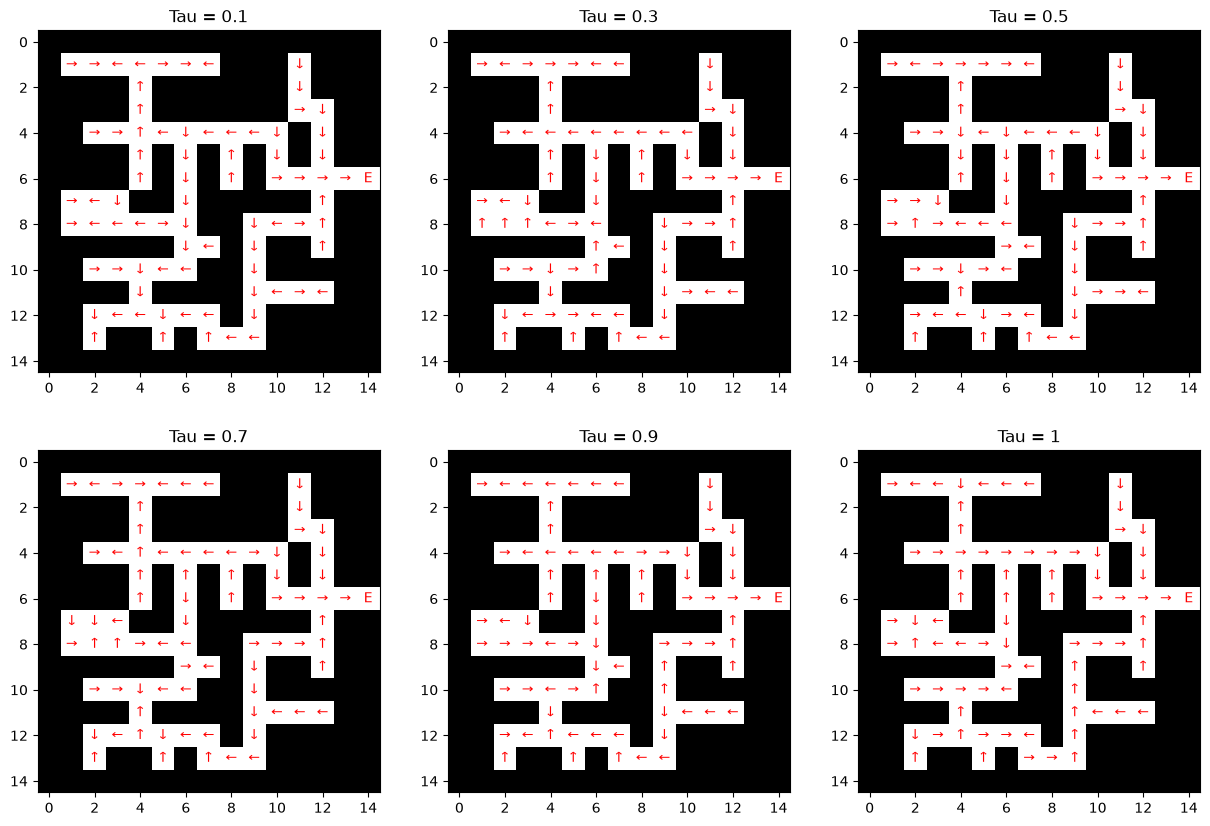

In [54]:


plt.subplots(2, 3, figsize=(15, 10))
for i, tau in enumerate(taus):
    plt.subplot(2, 3, i + 1)
    plt.title(f'Tau = {tau}')
    plot_policy(Maze, states, actions, results[i][1])


Text(0, 0.5, 'Average Steps')

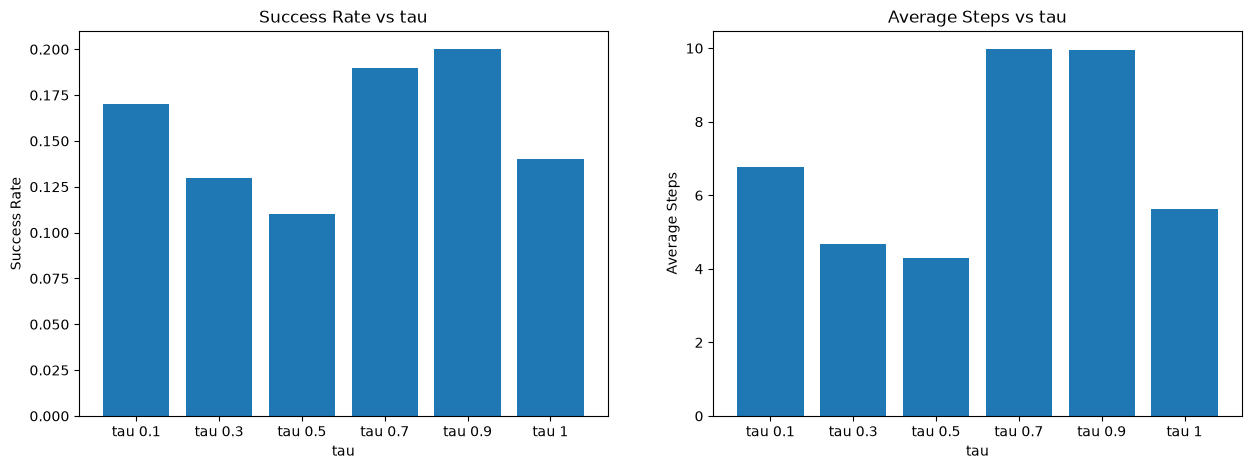

In [59]:

results_evaluation = []
for tau, pi, q_s_a in results:
    evaluation = evaluate_policy(pi, Maze, actions, n_episodes=100, iter_max=100)
    results_evaluation.append((tau, evaluation))

# bar plot for success rate, average return, and average steps
success_rates = [evaluation["success_rate"] for _, evaluation in results_evaluation]
average_returns = [evaluation["average_return"] for _, evaluation in results_evaluation]
average_steps = [evaluation["average_steps"] for _, evaluation in results_evaluation]


# bar on one figure with 3 subplots

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.bar([f"tau {tau}" for tau, _ in results_evaluation], success_rates)
plt.title("Success Rate vs tau")
plt.xlabel("tau")
plt.ylabel("Success Rate")



plt.subplot(1, 2, 2)
plt.bar([f"tau {tau}" for tau, _ in results_evaluation], average_steps)
plt.title("Average Steps vs tau")
plt.xlabel("tau")
plt.ylabel("Average Steps")


# n-step estimation

In [ ]:
# https://techielearn.com/tutorials/reinforcement-learning/n-step-td-prediction/introduction-to-n-step-td-prediction
# I use the algorithm from the link above to implement the n-step TD prediction algorithm. The main difference is that I use a list of episodes instead of a single episode, and I use the process_episode function to extract the state, action, reward, and next_state from each step in the episode. I also use the get_states_from_Maze function to get the states, exit_state, and init_states from the Maze.
def n_step_estimation(pi, Maze, n,  alpha=0.1, gamma=.9, max_iter=100):


    states, exit_state, init_states = get_states_from_Maze(Maze)
    V = np.zeros(len(states))  #
    for s in range(len(states)):
        if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  
            V[s] = 0  # Set value of exit state to 0
        else:
            V[s] = np.random.rand()
    
    episodes = [
        generate_episode_from_policy(init_states[np.random.randint(len(init_states))],  Maze, actions, pi=pi, iter_max=100) 
        for _ in range(max_iter)]
    for _, episode in enumerate(episodes):
        T = len(episode)
         
        for t, step in enumerate(episode):
            state, action, reward, next_state = process_episode(step)
    
            tau = t - n + 1
            if tau >= 0:
                G = 0.0
                for i in range(min(n, T - tau)):
                    G += (gamma ** i) * episode[tau + i][2]  
                    
                if tau + n < T:
                    G += (gamma ** n) * V[process_episode(episode[tau + n])[0]]  
                    
                V[state] += alpha * (G - V[state])
    return V


v = n_step_estimation(pi, Maze, n=4, alpha=0.1, gamma=.9, max_iter=1000)


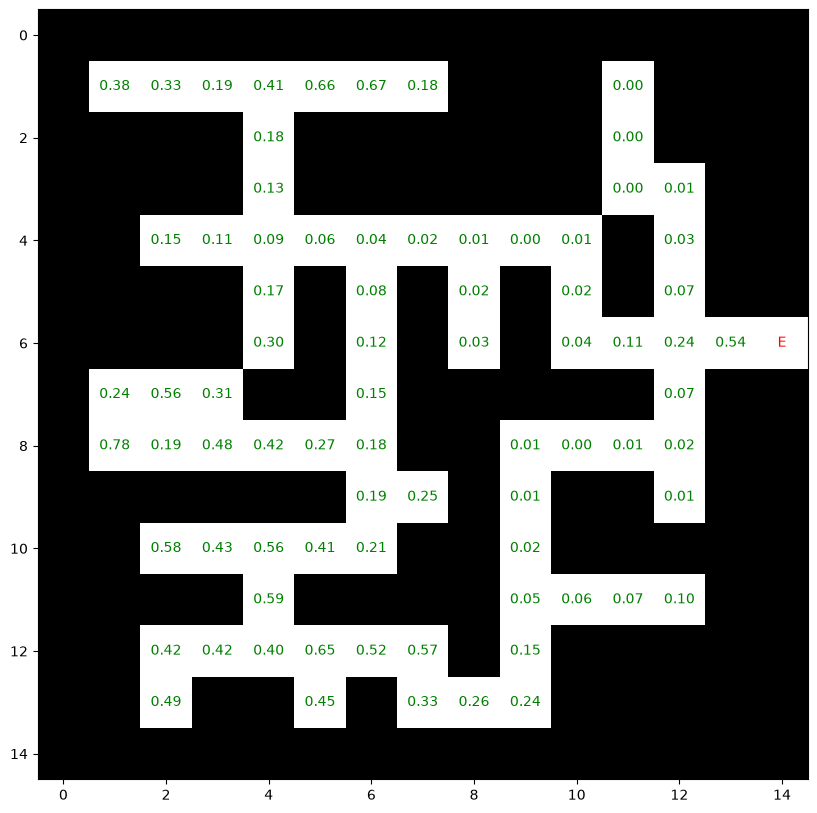

In [86]:
plot_values(Maze, v)

# N Step Sarsa control

In [87]:
# https://techielearn.com/tutorials/reinforcement-learning/n-step-td-prediction/introduction-to-n-step-td-prediction
# I use the algorithm from the link above to implement the n-step TD prediction algorithm. 
def n_step_sarsa(pi, Maze, n, alpha=0.1, epsilon=0.1,  gamma=.9, max_iter=100):

    states, exit_state, init_states = get_states_from_Maze(Maze)
    q_s_a = np.zeros((len(states), len(actions)))
    
    for s in range(len(states)):
        if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  
            continue  # Skip the exit state
        q_s_a[s] = np.random.rand(len(actions))
    pi = get_epsilon_greedy_policy(q_s_a, states, epsilon)
	
    # states, exit_state, init_states = get_states_from_Maze(Maze)
    # V = np.zeros(len(states))  #
    # for s in range(len(states)):
    #     if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  
    #         V[s] = 0  # Set value of exit state to 0
    #     else:
    #         V[s] = np.random.rand()
    
    episodes = [
        generate_episode_from_policy(init_states[np.random.randint(len(init_states))],  Maze, actions, pi=pi, iter_max=100) 
        for _ in range(max_iter)]
    for _, episode in enumerate(episodes):
        T = len(episode)
         
        for t, step in enumerate(episode):
            state, action, reward, next_state = process_episode(step)
    
            tau = t - n + 1
            if tau >= 0:
                G = 0.0
                for i in range(min(n, T - tau)):
                    G += (gamma ** i) * episode[tau + i][2]  
                    
                if tau + n < T:
                    episode_tau_n = episode[tau + n]
                    state_tau_n, action_tau_n, reward_tau_n, next_state_tau_n = process_episode(episode_tau_n)
                    G += (gamma ** n) * q_s_a[state_tau_n, action_tau_n]  
                    
                q_s_a[state, action] += alpha * (G - q_s_a[state, action])
                pi = get_epsilon_greedy_policy(q_s_a, states, epsilon)
                
    return pi, q_s_a




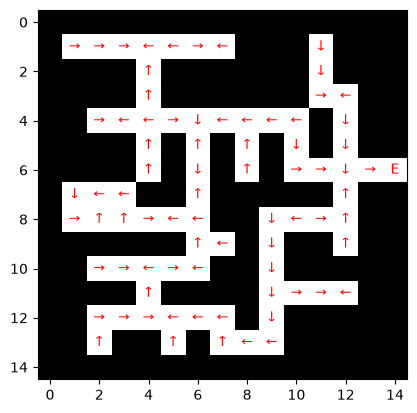

In [93]:

pi , q_s_a = n_step_sarsa(pi, Maze, n=4, alpha=.1, epsilon=0.1, gamma=.9, max_iter=1000)

plot_policy(Maze, states, actions, pi)

In [94]:
n_list = [ 2, 4, 6, 8, 10]

results = []
for n  in n_list:
    pi, q_s_a = n_step_sarsa(pi, Maze, n=n, alpha=.1, epsilon=0.1, gamma=.9, max_iter=1000)
    results.append((n, pi, q_s_a))  # Store the sum of values for comparison

	

Text(0, 0.5, 'Average Steps')

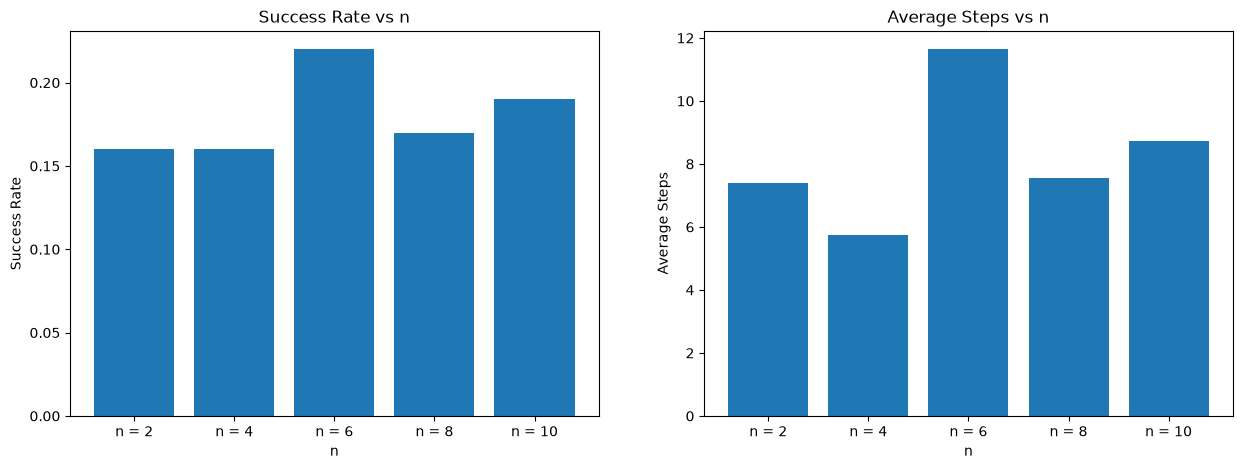

In [96]:

results_evaluation = []
for n, pi, q_s_a in results:
    evaluation = evaluate_policy(pi, Maze, actions, n_episodes=100, iter_max=100)
    results_evaluation.append((n, evaluation))

# bar plot for success rate, average return, and average steps
success_rates = [evaluation["success_rate"] for _, evaluation in results_evaluation]
average_returns = [evaluation["average_return"] for _, evaluation in results_evaluation]
average_steps = [evaluation["average_steps"] for _, evaluation in results_evaluation]


# bar on one figure with 3 subplots

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.bar([f"n = {n}" for n, _ in results_evaluation], success_rates)
plt.title("Success Rate vs n")
plt.xlabel("n")
plt.ylabel("Success Rate")



plt.subplot(1, 2, 2)
plt.bar([f"n = {n}" for n, _ in results_evaluation], average_steps)
plt.title("Average Steps vs n")
plt.xlabel("n")
plt.ylabel("Average Steps")
